In [1]:
import numpy as np
from collections import defaultdict
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Crippen
from rdkit.Chem.Scaffolds import MurckoScaffold
RDLogger.DisableLog("rdApp.*")

DESC = {
    "MolWt":      Descriptors.MolWt,          # size
    "LogP":       Crippen.MolLogP,            # greasiness
    "TPSA":       Descriptors.TPSA,           # polar surface area
    "HBD":        Descriptors.NumHDonors,
    "HBA":        Descriptors.NumHAcceptors,
    "RotB":       Descriptors.NumRotatableBonds,
    "Rings":      Descriptors.RingCount,
    "AromRings":  Descriptors.NumAromaticRings,
    "FracCSP3":   Descriptors.FractionCSP3,
    "HeavyAtoms": Descriptors.HeavyAtomCount,
    "MolMR":      Crippen.MolMR,
    "NOCount":    Descriptors.NOCount,
}

def describe(smiles_list):
    rows, keep = [], []
    for i, smi in enumerate(smiles_list):
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        rows.append([f(mol) for f in DESC.values()])
        keep.append(i)
    return pd.DataFrame(rows, columns=list(DESC)), keep

bbb = bbb.dropna(subset=["SMILES", "BBB+/BBB-"])
bbb_smiles = bbb["SMILES"].tolist()
Xb_df, keep = describe(bbb_smiles)
yb = (bbb["BBB+/BBB-"].values[keep] == "BBB+").astype(int)
bbb_smiles = [bbb_smiles[i] for i in keep]

print("molecules:", Xb_df.shape)
print("BBB+ :", int(yb.sum()), "   BBB- :", int((yb == 0).sum()))
Xb_df.describe().round(1)

NameError: name 'bbb' is not defined

In [2]:
import pandas as pd

url = ("https://raw.githubusercontent.com/theochem/B3DB/main/"
       "B3DB/B3DB_classification.tsv")
bbb = pd.read_csv(url, sep="\t")

print(bbb.shape)


(7807, 12)


In [3]:
import numpy as np
from collections import defaultdict
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Crippen
from rdkit.Chem.Scaffolds import MurckoScaffold
RDLogger.DisableLog("rdApp.*")

DESC = {
    "MolWt":      Descriptors.MolWt,          # size
    "LogP":       Crippen.MolLogP,            # greasiness
    "TPSA":       Descriptors.TPSA,           # polar surface area
    "HBD":        Descriptors.NumHDonors,
    "HBA":        Descriptors.NumHAcceptors,
    "RotB":       Descriptors.NumRotatableBonds,
    "Rings":      Descriptors.RingCount,
    "AromRings":  Descriptors.NumAromaticRings,
    "FracCSP3":   Descriptors.FractionCSP3,
    "HeavyAtoms": Descriptors.HeavyAtomCount,
    "MolMR":      Crippen.MolMR,
    "NOCount":    Descriptors.NOCount,
}

def describe(smiles_list):
    rows, keep = [], []
    for i, smi in enumerate(smiles_list):
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        rows.append([f(mol) for f in DESC.values()])
        keep.append(i)
    return pd.DataFrame(rows, columns=list(DESC)), keep

bbb = bbb.dropna(subset=["SMILES", "BBB+/BBB-"])
bbb_smiles = bbb["SMILES"].tolist()
Xb_df, keep = describe(bbb_smiles)
yb = (bbb["BBB+/BBB-"].values[keep] == "BBB+").astype(int)
bbb_smiles = [bbb_smiles[i] for i in keep]

print("molecules:", Xb_df.shape)
print("BBB+ :", int(yb.sum()), "   BBB- :", int((yb == 0).sum()))
Xb_df.describe().round(1)

molecules: (7805, 12)
BBB+ : 4956    BBB- : 2849


,MolWt,LogP,TPSA,HBD,HBA,RotB,Rings,AromRings,FracCSP3,HeavyAtoms,MolMR,NOCount
count,7805.0,7805.0,7805.0,7805.0,7805.0,7805.0,7805.0,7805.0,7805.0,7805.0,7805.0,7805.0
mean,385.5,2.4,87.0,2.0,5.3,4.8,3.3,1.3,0.5,26.9,101.5,6.2
std,170.9,2.2,67.7,2.3,3.7,3.6,1.6,1.1,0.2,12.0,43.1,4.3
min,6.9,-8.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
25%,285.3,1.2,41.5,1.0,3.0,2.0,2.0,0.0,0.3,20.0,78.1,3.0
50%,362.5,2.5,72.7,1.0,4.0,4.0,3.0,1.0,0.5,26.0,97.3,5.0
75%,451.6,3.8,107.6,3.0,6.0,6.0,4.0,2.0,0.7,31.0,116.6,8.0
max,1882.3,12.6,662.4,24.0,33.0,53.0,16.0,8.0,1.0,136.0,517.7,42.0


In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, roc_auc_score)

def scaffold_split(smiles, frac_train=0.8):
    groups = defaultdict(list)
    for i, smi in enumerate(smiles):
        try:
            core = MurckoScaffold.MurckoScaffoldSmiles(smiles=smi,
                                                       includeChirality=False)
        except Exception:
            core = f"__bad__{i}"
        groups[core].append(i)
    sets = sorted(groups.values(), key=len, reverse=True)
    n_train = int(frac_train * len(smiles))
    tr, te = [], []
    for s in sets:
        (tr if len(tr) < n_train else te).extend(s)
    return tr, te

btr, bte = scaffold_split(bbb_smiles)
Xb = Xb_df.values

print("train:", len(btr), " test:", len(bte))
print("BBB+ share — train:", round(yb[btr].mean(), 3),
      " test:", round(yb[bte].mean(), 3))
print()

bbb_models = {
    "Random Forest": RandomForestClassifier(n_estimators=500, n_jobs=-1,
                                            random_state=42,
                                            class_weight="balanced"),
    "Logistic Regression": Pipeline([("sc", StandardScaler()),
                        ("m", LogisticRegression(max_iter=2000,
                                                 class_weight="balanced"))]),
}

for name, m in bbb_models.items():
    m.fit(Xb[btr], yb[btr])
    pred = m.predict(Xb[bte])
    prob = m.predict_proba(Xb[bte])[:, 1]
    print(f"{name}: acc {accuracy_score(yb[bte], pred):.3f} | "
          f"prec {precision_score(yb[bte], pred):.3f} | "
          f"rec {recall_score(yb[bte], pred):.3f} | "
          f"auc {roc_auc_score(yb[bte], prob):.3f}")

train: 6244  test: 1561
BBB+ share — train: 0.654  test: 0.559

Random Forest: acc 0.704 | prec 0.684 | rec 0.875 | auc 0.794
Logistic Regression: acc 0.691 | prec 0.687 | rec 0.824 | auc 0.717


In [5]:
from rdkit.Chem import rdFingerprintGenerator
from sklearn.metrics import classification_report

gen1 = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
fp_rows = [gen1.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in bbb_smiles]
Xb_fp = np.array(fp_rows, dtype=np.uint8)

Xb_comb = np.hstack([Xb, Xb_fp])
print("combined features:", Xb_comb.shape)

rf_bbb = RandomForestClassifier(n_estimators=500, n_jobs=-1,
                                random_state=42, class_weight="balanced")
rf_bbb.fit(Xb_comb[btr], yb[btr])
prob = rf_bbb.predict_proba(Xb_comb[bte])[:, 1]
pred = rf_bbb.predict(Xb_comb[bte])

print("AUC:", round(roc_auc_score(yb[bte], prob), 3))
print()
print(classification_report(yb[bte], pred,
                           target_names=["BBB- (stays out)", "BBB+ (enters)"]))

combined features: (7805, 1036)
AUC: 0.827

                  precision    recall  f1-score   support

BBB- (stays out)       0.79      0.44      0.57       688
   BBB+ (enters)       0.67      0.91      0.77       873

        accuracy                           0.70      1561
       macro avg       0.73      0.68      0.67      1561
    weighted avg       0.73      0.70      0.68      1561



In [6]:
print(f"{'cut':>6} {'n called BBB-':>15} {'precision':>11}")
for t in [0.50, 0.40, 0.35, 0.30, 0.25, 0.20]:
    called = prob < t
    n = int(called.sum())
    if n == 0:
        continue
    prec = (yb[bte][called] == 0).mean()
    print(f"{t:6.2f} {n:15d} {prec:11.3f}")

   cut   n called BBB-   precision
  0.50             383       0.794
  0.40             248       0.831
  0.35             192       0.875
  0.30             142       0.873
  0.25             114       0.921
  0.20              81       0.963


In [7]:
import joblib, os
os.makedirs("models", exist_ok=True)
joblib.dump(rf_bbb, "models/bbb_rf.joblib")

CUT = 0.25

tlr = pd.read_csv("data/tlr7_labelled.csv")
actives = tlr[tlr["active"] == 1].reset_index(drop=True)
print("known potent TLR7 blockers:", len(actives))

# build exactly the same features the BBB model was trained on
desc_df, keep = describe(actives["smiles"].tolist())
act = actives.iloc[keep].reset_index(drop=True)
fps = [gen1.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in act["smiles"]]
Xs = np.hstack([desc_df.values, np.array(fps, dtype=np.uint8)])

act["bbb_plus_prob"] = rf_bbb.predict_proba(Xs)[:, 1]

short = (act[act["bbb_plus_prob"] < CUT]
           .sort_values("pchembl", ascending=False)
           .reset_index(drop=True))
short.to_csv("data/shortlist.csv", index=False)

print("shortlist:", len(short), "compounds")
print()
short[["molecule_chembl_id", "pchembl", "bbb_plus_prob"]].head(20)

known potent TLR7 blockers: 3013
shortlist: 0 compounds



,molecule_chembl_id,pchembl,bbb_plus_prob


In [8]:
# 1. sanity check: are the features built the same way?
print("columns match:", list(desc_df.columns) == list(Xb_df.columns))
print("shapes:", Xs.shape, "vs training", Xb_comb.shape)
print()

# 2. what does the model actually think?
print(act["bbb_plus_prob"].describe().round(3))
print()
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    print(f"  prob < {t}: {int((act['bbb_plus_prob'] < t).sum())} compounds")
print()

# 3. how do these compounds compare to the BBB training set?
cmp = pd.DataFrame({
    "TLR7 actives": desc_df.median(),
    "B3DB": Xb_df.median(),
}).round(1)
print(cmp)

columns match: True
shapes: (3013, 1036) vs training (7805, 1036)

count    3013.000
mean        0.608
std         0.085
min         0.356
25%         0.545
50%         0.598
75%         0.669
max         0.875
Name: bbb_plus_prob, dtype: float64

  prob < 0.2: 0 compounds
  prob < 0.3: 0 compounds
  prob < 0.4: 6 compounds
  prob < 0.5: 257 compounds
  prob < 0.6: 1542 compounds
  prob < 0.7: 2540 compounds
  prob < 0.8: 2980 compounds

            TLR7 actives   B3DB
MolWt              473.6  362.5
LogP                 4.9    2.5
TPSA                78.3   72.7
HBD                  1.0    1.0
HBA                  5.0    4.0
RotB                 5.0    4.0
Rings                5.0    3.0
AromRings            4.0    1.0
FracCSP3             0.5    0.5
HeavyAtoms          35.0   26.0
MolMR              137.7   97.3
NOCount              7.0    5.0


In [9]:
from rdkit import DataStructs

genS = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
b3_fps  = [genS.GetFingerprint(Chem.MolFromSmiles(s)) for s in bbb_smiles]
tlr_fps = [genS.GetFingerprint(Chem.MolFromSmiles(s)) for s in act["smiles"]]

nn = [max(DataStructs.BulkTanimotoSimilarity(fp, b3_fps)) for fp in tlr_fps]
act["nn_sim"] = nn

print(pd.Series(nn).describe().round(3))
print("share with nearest neighbour below 0.4:",
      round((np.array(nn) < 0.4).mean(), 3))

count    3013.000
mean        0.241
std         0.031
min         0.172
25%         0.220
50%         0.239
75%         0.259
max         0.415
dtype: float64
share with nearest neighbour below 0.4: 0.999


In [10]:
d = desc_df.copy()
for c in ["molecule_chembl_id", "pchembl", "smiles", "bbb_plus_prob", "nn_sim"]:
    d[c] = act[c].values

rules = {
    "TPSA > 90":   d["TPSA"]  > 90,
    "MolWt > 450": d["MolWt"] > 450,
    "HBD >= 2":    d["HBD"]   >= 2,
    "RotB >= 8":   d["RotB"]  >= 8,
}
for name, ok in rules.items():
    d[name] = ok.astype(int)
    print(f"{name:14s} {int(ok.sum()):5d} of {len(d)}")

d["peripheral_score"] = sum(rules.values()).astype(int)
print()
print(d["peripheral_score"].value_counts().sort_index())

TPSA > 90        721 of 3013
MolWt > 450     2067 of 3013
HBD >= 2        1370 of 3013
RotB >= 8        247 of 3013

peripheral_score
0     388
1    1408
2     727
3     417
4      73
Name: count, dtype: int64


In [11]:
CUT = 3

final = (d[d["peripheral_score"] >= CUT]
           .sort_values(["peripheral_score", "pchembl"], ascending=[False, False])
           .reset_index(drop=True))
final.to_csv("data/shortlist_peripheral.csv", index=False)

print("shortlist:", len(final), " (top tier, score 4:",
      int((final["peripheral_score"] == 4).sum()), ")")
print()
print("BBB model's average probability, by rule score:")
print(d.groupby("peripheral_score")["bbb_plus_prob"].mean().round(3))
print()
final[["molecule_chembl_id", "pchembl", "peripheral_score",
       "TPSA", "MolWt", "HBD", "RotB", "bbb_plus_prob"]].head(15)

shortlist: 490  (top tier, score 4: 73 )

BBB model's average probability, by rule score:
peripheral_score
0    0.719
1    0.630
2    0.567
3    0.522
4    0.483
Name: bbb_plus_prob, dtype: float64



,molecule_chembl_id,pchembl,peripheral_score,TPSA,MolWt,HBD,RotB,bbb_plus_prob
0,CHEMBL5837680,9.700,4,121.41,515.662,3,8,0.412329
1,CHEMBL5991391,9.520,4,96.78,530.673,2,8,0.507071
2,CHEMBL5836817,9.400,4,96.78,504.635,2,9,0.483432
3,CHEMBL5809111,9.100,4,105.89,574.774,2,9,0.496963
4,CHEMBL5966566,9.100,4,96.78,544.700,2,9,0.489881
5,CHEMBL5855314,9.090,4,102.38,464.614,3,8,0.570276
6,CHEMBL5980739,9.000,4,127.29,516.643,3,8,0.472246
7,CHEMBL5756892,8.890,4,107.78,518.662,3,8,0.432997
8,CHEMBL5825757,8.890,4,100.80,492.624,2,8,0.541599
9,CHEMBL5915731,8.890,4,98.99,544.700,2,8,0.487293


In [12]:
d.to_csv("data/actives_scored.csv", index=False)

saved 3 figures to figures/


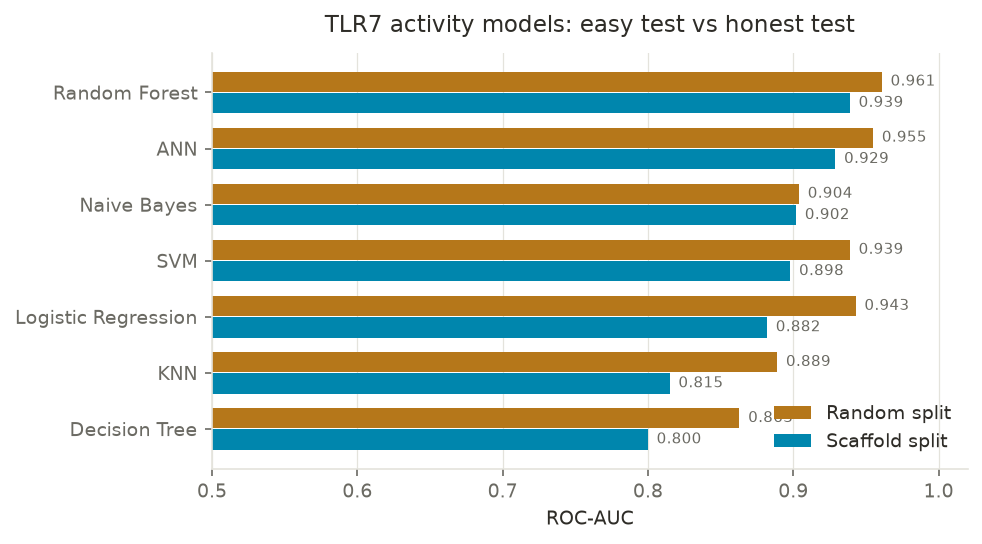

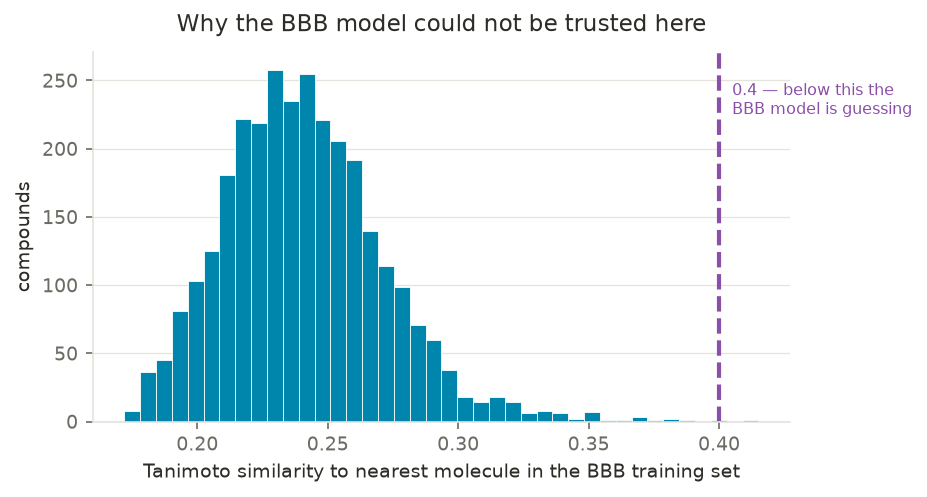

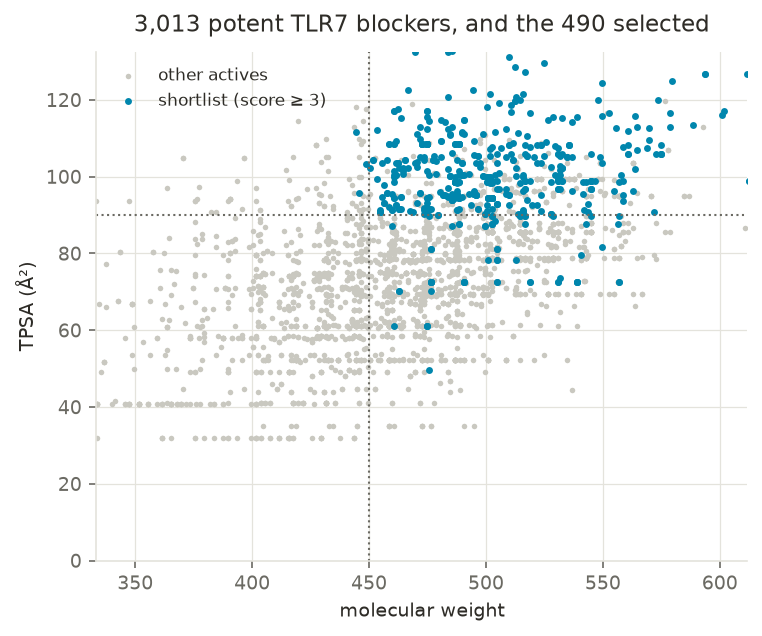

In [13]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

TEAL, AMBER, PURPLE = "#0086AD", "#B5771A", "#8A4FA8"
INK, MUTED, GRID = "#2E2C27", "#6B6A63", "#E4E3DC"
plt.rcParams.update({
    "figure.dpi": 150, "font.size": 9,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})

# ---- Figure 1: the two splits side by side ----
r = pd.read_csv("data/model_results.csv")
s = pd.read_csv("data/model_results_scaffold.csv")
m = r[["model", "roc auc"]].rename(columns={"roc auc": "random"})
m["scaffold"] = s["roc auc"].values
m = m.sort_values("scaffold").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
yp, h = np.arange(len(m)), 0.36
ax.barh(yp + h/2 + 0.01, m["random"],   height=h, color=AMBER, label="Random split")
ax.barh(yp - h/2 - 0.01, m["scaffold"], height=h, color=TEAL,  label="Scaffold split")
for y, v in zip(yp + h/2 + 0.01, m["random"]):
    ax.text(v + 0.006, y, f"{v:.3f}", va="center", fontsize=7, color=MUTED)
for y, v in zip(yp - h/2 - 0.01, m["scaffold"]):
    ax.text(v + 0.006, y, f"{v:.3f}", va="center", fontsize=7, color=MUTED)
ax.set_yticks(yp); ax.set_yticklabels(m["model"])
ax.set_xlim(0.5, 1.02); ax.set_xlabel("ROC-AUC")
ax.set_title("TLR7 activity models: easy test vs honest test", pad=10)
ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
fig.savefig("figures/fig1_model_comparison.png", bbox_inches="tight")

# ---- Figure 2: the applicability domain ----
d = pd.read_csv("data/actives_scored.csv")
fig, ax = plt.subplots(figsize=(6.0, 3.2))
ax.hist(d["nn_sim"], bins=40, color=TEAL, edgecolor="white", linewidth=0.4)
ax.axvline(0.4, color=PURPLE, lw=2, ls="--")
ax.text(0.405, ax.get_ylim()[1]*0.92,
        "0.4 — below this the\nBBB model is guessing",
        fontsize=7.5, color=PURPLE, va="top")
ax.set_xlabel("Tanimoto similarity to nearest molecule in the BBB training set")
ax.set_ylabel("compounds")
ax.set_title("Why the BBB model could not be trusted here", pad=10)
ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
fig.savefig("figures/fig2_applicability_domain.png", bbox_inches="tight")

# ---- Figure 3: the shortlist in property space ----
sel = d["peripheral_score"] >= 3
fig, ax = plt.subplots(figsize=(5.6, 4.4))
ax.scatter(d.loc[~sel, "MolWt"], d.loc[~sel, "TPSA"], s=7,
           color="#C9C8C0", lw=0, label="other actives")
ax.scatter(d.loc[sel, "MolWt"], d.loc[sel, "TPSA"], s=11,
           color=TEAL, lw=0, label="shortlist (score ≥ 3)")
ax.axvline(450, color=MUTED, lw=1, ls=":")
ax.axhline(90,  color=MUTED, lw=1, ls=":")
ax.set_xlim(d["MolWt"].quantile(0.002), d["MolWt"].quantile(0.998))
ax.set_ylim(0, d["TPSA"].quantile(0.998))
ax.set_xlabel("molecular weight"); ax.set_ylabel("TPSA (Å²)")
ax.set_title(f"3,013 potent TLR7 blockers, and the {int(sel.sum())} selected", pad=10)
ax.legend(frameon=False, loc="upper left", fontsize=8)
ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
fig.savefig("figures/fig3_shortlist.png", bbox_inches="tight")

print("saved 3 figures to figures/")

In [14]:
d.to_csv("data/actives_scored.csv", index=False)
print("saved")

saved


saved 3 figures to figures/


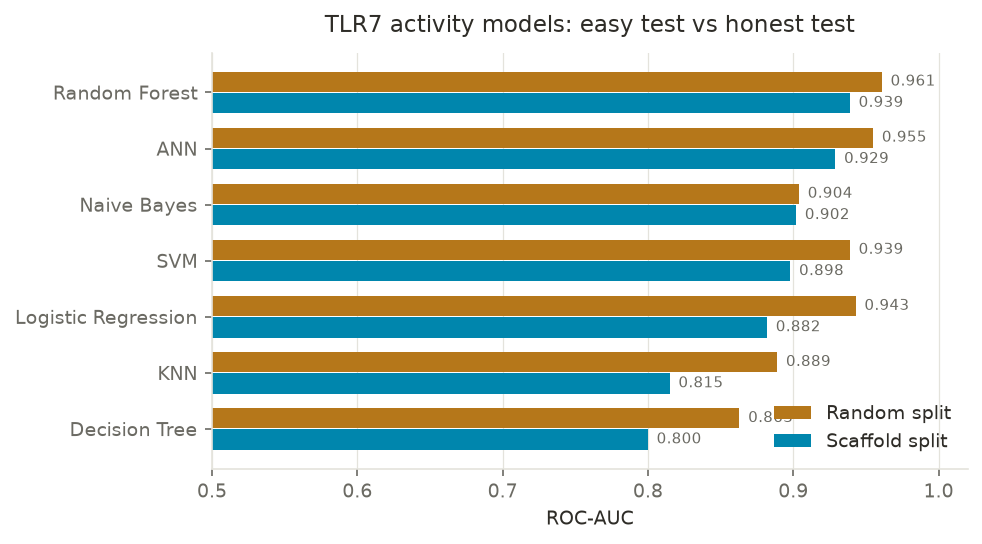

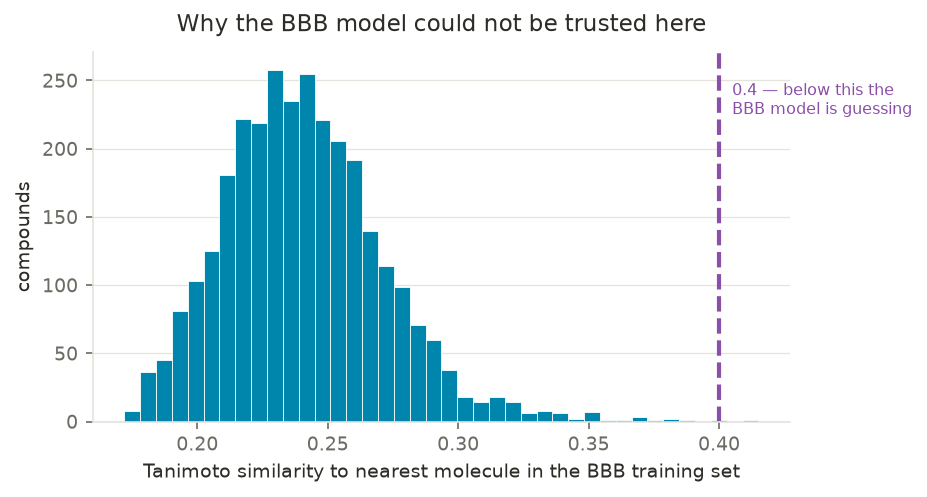

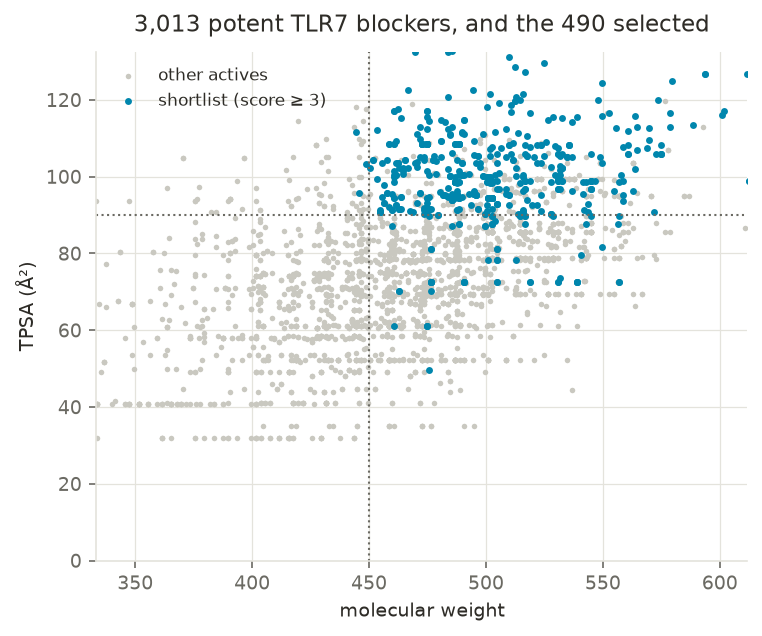

In [15]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

TEAL, AMBER, PURPLE = "#0086AD", "#B5771A", "#8A4FA8"
INK, MUTED, GRID = "#2E2C27", "#6B6A63", "#E4E3DC"
plt.rcParams.update({
    "figure.dpi": 150, "font.size": 9,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})

# ---- Figure 1: the two splits side by side ----
r = pd.read_csv("data/model_results.csv")
s = pd.read_csv("data/model_results_scaffold.csv")
m = r[["model", "roc auc"]].rename(columns={"roc auc": "random"})
m["scaffold"] = s["roc auc"].values
m = m.sort_values("scaffold").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
yp, h = np.arange(len(m)), 0.36
ax.barh(yp + h/2 + 0.01, m["random"],   height=h, color=AMBER, label="Random split")
ax.barh(yp - h/2 - 0.01, m["scaffold"], height=h, color=TEAL,  label="Scaffold split")
for y, v in zip(yp + h/2 + 0.01, m["random"]):
    ax.text(v + 0.006, y, f"{v:.3f}", va="center", fontsize=7, color=MUTED)
for y, v in zip(yp - h/2 - 0.01, m["scaffold"]):
    ax.text(v + 0.006, y, f"{v:.3f}", va="center", fontsize=7, color=MUTED)
ax.set_yticks(yp); ax.set_yticklabels(m["model"])
ax.set_xlim(0.5, 1.02); ax.set_xlabel("ROC-AUC")
ax.set_title("TLR7 activity models: easy test vs honest test", pad=10)
ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
fig.savefig("figures/fig1_model_comparison.png", bbox_inches="tight")

# ---- Figure 2: the applicability domain ----
d = pd.read_csv("data/actives_scored.csv")
fig, ax = plt.subplots(figsize=(6.0, 3.2))
ax.hist(d["nn_sim"], bins=40, color=TEAL, edgecolor="white", linewidth=0.4)
ax.axvline(0.4, color=PURPLE, lw=2, ls="--")
ax.text(0.405, ax.get_ylim()[1]*0.92,
        "0.4 — below this the\nBBB model is guessing",
        fontsize=7.5, color=PURPLE, va="top")
ax.set_xlabel("Tanimoto similarity to nearest molecule in the BBB training set")
ax.set_ylabel("compounds")
ax.set_title("Why the BBB model could not be trusted here", pad=10)
ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
fig.savefig("figures/fig2_applicability_domain.png", bbox_inches="tight")

# ---- Figure 3: the shortlist in property space ----
sel = d["peripheral_score"] >= 3
fig, ax = plt.subplots(figsize=(5.6, 4.4))
ax.scatter(d.loc[~sel, "MolWt"], d.loc[~sel, "TPSA"], s=7,
           color="#C9C8C0", lw=0, label="other actives")
ax.scatter(d.loc[sel, "MolWt"], d.loc[sel, "TPSA"], s=11,
           color=TEAL, lw=0, label="shortlist (score ≥ 3)")
ax.axvline(450, color=MUTED, lw=1, ls=":")
ax.axhline(90,  color=MUTED, lw=1, ls=":")
ax.set_xlim(d["MolWt"].quantile(0.002), d["MolWt"].quantile(0.998))
ax.set_ylim(0, d["TPSA"].quantile(0.998))
ax.set_xlabel("molecular weight"); ax.set_ylabel("TPSA (Å²)")
ax.set_title(f"3,013 potent TLR7 blockers, and the {int(sel.sum())} selected", pad=10)
ax.legend(frameon=False, loc="upper left", fontsize=8)
ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
fig.savefig("figures/fig3_shortlist.png", bbox_inches="tight")

print("saved 3 figures to figures/")